# NLP Assignment 2 — DFA and FST

This notebook implements the two tasks from the assignment:

1. **DFA** for valid simplified English words.
2. **FST** for noun morphology using the supplied `brown_nouns.txt`.

The notebook is designed for a **local Linux/Jupyter environment**.

> **Important:** Graphviz files are saved in a local `diagrams/` folder instead of `/mnt/data`, because `/mnt/data` may not exist on a normal Linux installation.


## Required files

Keep these two files in the same directory:

```text
NLP_Assignment_2_DFA_FST_LOCAL.ipynb
brown_nouns.txt
```

The notebook will create:

```text
diagrams/
    dfa_simplified_english.png
    fst_noun_pluralization.png

brown_nouns_fst_output.csv
```


In [1]:
# Imports
from pathlib import Path
from collections import Counter
import re
import os

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

try:
    from graphviz import Digraph
    GRAPHVIZ_AVAILABLE = True
except ImportError:
    GRAPHVIZ_AVAILABLE = False
    print("Python graphviz package is not installed.")
    print("Run: pip install graphviz")

print("Working directory:", Path.cwd())
print("Graphviz Python package available:", GRAPHVIZ_AVAILABLE)


Working directory: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-3
Graphviz Python package available: True


In [2]:
# Check that the Graphviz executable is installed.
import shutil

dot_executable = shutil.which("dot")

if dot_executable:
    print("Graphviz executable:", dot_executable)
    print("Graphviz is ready.")
else:
    print("Graphviz executable was not found.")
    print("On Ubuntu/Debian run:")
    print("  sudo apt update")
    print("  sudo apt install graphviz")


Graphviz executable: /usr/bin/dot
Graphviz is ready.


In [3]:
# Locate brown_nouns.txt in the current directory.
BROWN_PATH = Path("brown_nouns.txt")

if not BROWN_PATH.exists():
    raise FileNotFoundError(
        f"{BROWN_PATH.resolve()} was not found. "
        "Place brown_nouns.txt in the same directory as this notebook."
    )

with BROWN_PATH.open("r", encoding="utf-8", errors="ignore") as f:
    brown_words = [line.strip() for line in f if line.strip()]

# The DFA assignment defines simplified words using lowercase letters.
brown_words = [w for w in brown_words if re.fullmatch(r"[a-z]+", w)]
brown_unique = sorted(set(brown_words))

print("Brown noun file:", BROWN_PATH.resolve())
print("Total entries:", len(brown_words))
print("Unique lowercase nouns:", len(brown_unique))
print("\nFirst 30 nouns:")
print(brown_unique[:30])


Brown noun file: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-3/brown_nouns.txt
Total entries: 198756
Unique lowercase nouns: 17053

First 30 nouns:
['abandon', 'abandonment', 'abaringe', 'abasement', 'abberations', 'abbey', 'abbot', 'abbreviation', 'abbreviations', 'abdomen', 'abdominis', 'abduction', 'aberration', 'aberrations', 'abeyance', 'abilities', 'ability', 'abjection', 'ablation', 'abnormalities', 'abode', 'abolition', 'abolitionist', 'abolitionists', 'aborigine', 'aborigines', 'abortion', 'abortions', 'abreaction', 'abridgment']


# Part A — DFA

The assignment defines a valid simplified English word as:

- starting with a lowercase letter;
- followed by zero or more lowercase letters;
- containing no digits, spaces, punctuation, uppercase letters, or special characters.

### States

| State | Meaning |
|---|---|
| `q0` | Start state |
| `q1` | Valid lowercase word prefix |
| `q_dead` | Invalid/dead state |

`q1` is the accepting state.


In [4]:
# DFA transition table
dfa_compact = pd.DataFrame([
    ["q0", "a-z", "q1"],
    ["q0", "other", "q_dead"],
    ["q1", "a-z", "q1"],
    ["q1", "other", "q_dead"],
    ["q_dead", "any", "q_dead"],
], columns=["Current State", "Input Class", "Next State"])

display(dfa_compact)


,Current State,Input Class,Next State
0,q0,a-z,q1
1,q0,other,q_dead
2,q1,a-z,q1
3,q1,other,q_dead
4,q_dead,any,q_dead


In [5]:
# DFA implementation

LOWER = set("abcdefghijklmnopqrstuvwxyz")

def dfa_accepts(word: str) -> str:
    state = "q0"

    for ch in word:
        if state == "q0":
            state = "q1" if ch in LOWER else "q_dead"

        elif state == "q1":
            state = "q1" if ch in LOWER else "q_dead"

        else:
            state = "q_dead"

    return "Accepted" if state == "q1" else "Not Accepted"


examples = [
    "cat",
    "dog",
    "a",
    "zebra",
    "dog1",
    "1dog",
    "DogHouse",
    "Dog_house",
    " cats"
]

dfa_results = pd.DataFrame({
    "Input": examples,
    "Output": [dfa_accepts(x) for x in examples]
})

display(dfa_results)


,Input,Output
0,cat,Accepted
1,dog,Accepted
2,a,Accepted
3,zebra,Accepted
4,dog1,Not Accepted
5,1dog,Not Accepted
6,DogHouse,Not Accepted
7,Dog_house,Not Accepted
8,cats,Not Accepted


## DFA diagram

The diagram is generated with `dot.render()` and saved locally in the notebook directory under `diagrams/`.

No `/mnt/data` path is used.


DFA diagram saved to:
/home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-3/diagrams/dfa_simplified_english.png


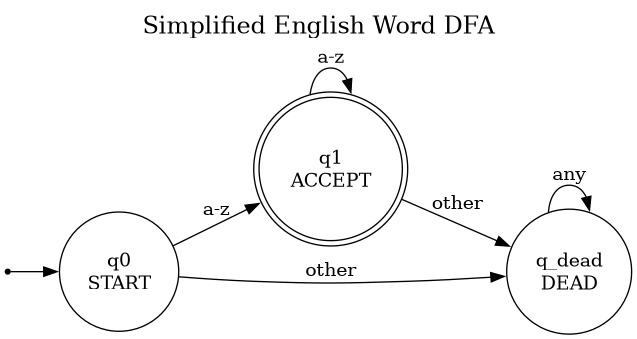

In [6]:
# Create a local output directory.
DIAGRAM_DIR = Path("diagrams")
DIAGRAM_DIR.mkdir(parents=True, exist_ok=True)

if not GRAPHVIZ_AVAILABLE:
    print("Install the Python package first: pip install graphviz")

elif not shutil.which("dot"):
    print("Install the Graphviz system package first:")
    print("sudo apt update")
    print("sudo apt install graphviz")

else:
    dot = Digraph("DFA", format="png")
    dot.attr(
        rankdir="LR",
        label="Simplified English Word DFA",
        labelloc="t",
        fontsize="18"
    )
    dot.attr("node", shape="circle")

    dot.node("start", "", shape="point")
    dot.node("q0", "q0\nSTART")
    dot.node("q1", "q1\nACCEPT", shape="doublecircle")
    dot.node("q_dead", "q_dead\nDEAD")

    dot.edge("start", "q0")
    dot.edge("q0", "q1", label="a-z")
    dot.edge("q0", "q_dead", label="other")
    dot.edge("q1", "q1", label="a-z")
    dot.edge("q1", "q_dead", label="other")
    dot.edge("q_dead", "q_dead", label="any")

    dfa_graph = dot.render(
        str(DIAGRAM_DIR / "dfa_simplified_english"),
        cleanup=True
    )

    print("DFA diagram saved to:")
    print(Path(dfa_graph).resolve())

    display(Image(filename=dfa_graph))


# Part B — FST

The assignment asks for grammatical features such as:

```text
foxes = fox+N+PL
fox   = fox+N+SG
```

where:

- `N` = Noun
- `SG` = Singular
- `PL` = Plural

### Pluralization rules

| Rule | Condition | Example |
|---|---|---|
| E insertion | ends in `s`, `z`, `x`, `ch`, `sh` | `fox → foxes` |
| Y replacement | ends in `y` | `try → tries` |
| S addition | otherwise | `bag → bags` |


In [7]:
# FST rule / transition table

fst_rules = pd.DataFrame([
    ["q_suffix", "s, z, x, ch, sh", "stem + e + s", "N+PL"],
    ["q_suffix", "y", "stem_without_y + i + e + s", "N+PL"],
    ["q_suffix", "other", "stem + s", "N+PL"],
], columns=[
    "State",
    "Input condition",
    "Output operation",
    "Feature"
])

display(fst_rules)


,State,Input condition,Output operation,Feature
0,q_suffix,"s, z, x, ch, sh",stem + e + s,N+PL
1,q_suffix,y,stem_without_y + i + e + s,N+PL
2,q_suffix,other,stem + s,N+PL


In [8]:
# Table-driven plural generation

PLURAL_SUFFIX_TABLE = [
    ("ch", "stem+es"),
    ("sh", "stem+es"),
    ("s", "stem+es"),
    ("z", "stem+es"),
    ("x", "stem+es"),
    ("y", "stem_without_y+ies"),
    ("", "stem+s")
]

def apply_fst_plural_transition(root: str) -> str:
    # Longest suffix is checked first.
    for suffix, operation in sorted(
        PLURAL_SUFFIX_TABLE,
        key=lambda item: len(item[0]),
        reverse=True
    ):
        if suffix == "" or root.endswith(suffix):

            if operation == "stem+es":
                return root + "es"

            elif operation == "stem_without_y+ies":
                return root[:-1] + "ies"

            elif operation == "stem+s":
                return root + "s"

    raise ValueError("No FST transition found")


def fst_generate(root: str, number: str) -> str:
    if not re.fullmatch(r"[a-z]+", root):
        return "Invalid Word"

    if number == "SG":
        return root

    if number == "PL":
        return apply_fst_plural_transition(root)

    return "Invalid Word"


generation_examples = pd.DataFrame([
    ("fox", "SG"),
    ("fox", "PL"),
    ("watch", "PL"),
    ("try", "PL"),
    ("bag", "PL"),
], columns=["Root", "Number"])

generation_examples["Generated Word"] = [
    fst_generate(root, number)
    for root, number in generation_examples.itertuples(index=False)
]

display(generation_examples)


,Root,Number,Generated Word
0,fox,SG,fox
1,fox,PL,foxes
2,watch,PL,watches
3,try,PL,tries
4,bag,PL,bags


## FST state diagram

This diagram shows the compact state structure used by the table-driven FST.


FST diagram saved to:
/home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-3/diagrams/fst_noun_pluralization.png


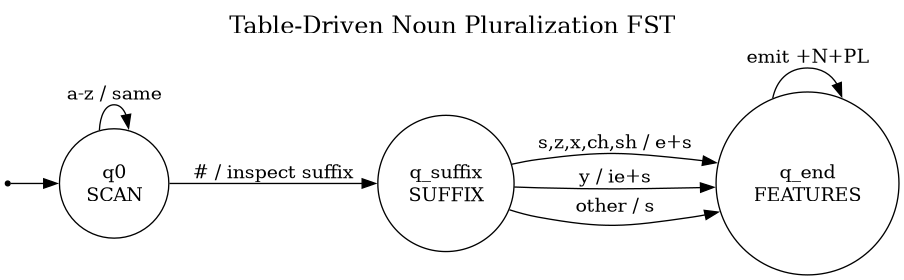

In [9]:
if not GRAPHVIZ_AVAILABLE:
    print("Install the Python package first: pip install graphviz")

elif not shutil.which("dot"):
    print("Install Graphviz:")
    print("sudo apt update")
    print("sudo apt install graphviz")

else:
    dot = Digraph("FST", format="png")
    dot.attr(
        rankdir="LR",
        label="Table-Driven Noun Pluralization FST",
        labelloc="t",
        fontsize="18"
    )
    dot.attr("node", shape="circle")

    dot.node("start", "", shape="point")
    dot.node("q0", "q0\nSCAN")
    dot.node("q_suffix", "q_suffix\nSUFFIX")
    dot.node("q_end", "q_end\nFEATURES")

    dot.edge("start", "q0")
    dot.edge("q0", "q0", label="a-z / same")
    dot.edge("q0", "q_suffix", label="# / inspect suffix")
    dot.edge(
        "q_suffix",
        "q_end",
        label="s,z,x,ch,sh / e+s"
    )
    dot.edge(
        "q_suffix",
        "q_end",
        label="y / ie+s"
    )
    dot.edge(
        "q_suffix",
        "q_end",
        label="other / s"
    )
    dot.edge("q_end", "q_end", label="emit +N+PL")

    fst_graph = dot.render(
        str(DIAGRAM_DIR / "fst_noun_pluralization"),
        cleanup=True
    )

    print("FST diagram saved to:")
    print(Path(fst_graph).resolve())

    display(Image(filename=fst_graph))


# FST analysis of the Brown noun corpus

For analysis, a surface word is assigned:

- `root+N+PL` if it can be generated by one of the plural rules **and the root exists in the supplied Brown noun vocabulary**.
- `word+N+SG` otherwise, provided it is a valid DFA word.
- `Invalid Word` if it fails the DFA.

The vocabulary check prevents incorrect generated forms such as `foxs` from being accepted when the valid form is `foxes`.


In [10]:
brown_vocab = set(brown_unique)

def plural_candidates_for_surface(word: str):
    candidates = []

    # Y replacement: try -> tries
    if word.endswith("ies") and len(word) > 3:
        candidates.append(word[:-3] + "y")

    # E insertion: foxes -> fox
    for suffix in ("ches", "shes", "ses", "zes", "xes"):
        if word.endswith(suffix) and len(word) > len(suffix):
            candidates.append(word[:-2])

    # S addition: bags -> bag
    if (
        word.endswith("s")
        and not word.endswith(
            ("ss", "ies", "ses", "zes", "xes", "ches", "shes")
        )
        and len(word) > 1
    ):
        candidates.append(word[:-1])

    return list(dict.fromkeys(candidates))


def fst_analyze(word: str) -> str:
    if dfa_accepts(word) != "Accepted":
        return "Invalid Word"

    for root in plural_candidates_for_surface(word):
        if (
            root in brown_vocab
            and fst_generate(root, "PL") == word
        ):
            return f"{root}+N+PL"

    return f"{word}+N+SG"


analysis_examples = [
    "fox",
    "foxes",
    "try",
    "tries",
    "bag",
    "bags",
    "foxs",
    "1dog"
]

display(pd.DataFrame({
    "Word": analysis_examples,
    "FST Output": [fst_analyze(w) for w in analysis_examples]
}))


,Word,FST Output
0,fox,fox+N+SG
1,foxes,fox+N+PL
2,try,try+N+SG
3,tries,try+N+PL
4,bag,bag+N+SG
5,bags,bag+N+PL
6,foxs,foxs+N+SG
7,1dog,Invalid Word


In [11]:
# Analyze every unique Brown noun.
analysis_rows = [
    (word, fst_analyze(word))
    for word in brown_unique
]

fst_output = pd.DataFrame(
    analysis_rows,
    columns=["Word", "Morphological Analysis"]
)

def split_analysis(text):
    if text == "Invalid Word":
        return pd.Series(["", "", "", "Invalid Word"])

    root, category, number = text.split("+")
    return pd.Series([root, category, number, "Valid"])


fst_output[
    ["Root", "Category", "Number", "Status"]
] = fst_output["Morphological Analysis"].apply(split_analysis)

display(fst_output.head(30))

print("Total unique nouns:", len(fst_output))
print("\nNumber distribution:")
display(
    fst_output["Number"]
    .value_counts()
    .rename_axis("Number")
    .to_frame("Count")
)


,Word,Morphological Analysis,Root,Category,Number,Status
0,abandon,abandon+N+SG,abandon,N,SG,Valid
1,abandonment,abandonment+N+SG,abandonment,N,SG,Valid
2,abaringe,abaringe+N+SG,abaringe,N,SG,Valid
3,abasement,abasement+N+SG,abasement,N,SG,Valid
4,abberations,abberations+N+SG,abberations,N,SG,Valid
5,abbey,abbey+N+SG,abbey,N,SG,Valid
6,abbot,abbot+N+SG,abbot,N,SG,Valid
7,abbreviation,abbreviation+N+SG,abbreviation,N,SG,Valid
8,abbreviations,abbreviation+N+PL,abbreviation,N,PL,Valid
9,abdomen,abdomen+N+SG,abdomen,N,SG,Valid


Total unique nouns: 17053

Number distribution:


,Count
Number,
SG,12856
PL,4197


In [12]:
# Save output next to the notebook.
output_csv = Path("brown_nouns_fst_output.csv")
fst_output.to_csv(output_csv, index=False)

print("Saved:")
print(output_csv.resolve())


Saved:
/home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-3/brown_nouns_fst_output.csv


# Validation — incorrect words

The assignment explicitly requires incorrect forms to return **Invalid Word**.

For example:

```text
foxs → Invalid Word
```

because the E-insertion rule produces:

```text
fox → foxes
```


In [13]:
validation = pd.DataFrame([
    {
        "Input": "fox",
        "Expected": "fox+N+SG",
        "Actual": fst_analyze("fox")
    },
    {
        "Input": "foxes",
        "Expected": "fox+N+PL",
        "Actual": fst_analyze("foxes")
    },
    {
        "Input": "watch",
        "Expected": "watch+N+SG",
        "Actual": fst_analyze("watch")
    },
    {
        "Input": "watches",
        "Expected": "watch+N+PL",
        "Actual": fst_analyze("watches")
    },
    {
        "Input": "try",
        "Expected": "try+N+SG",
        "Actual": fst_analyze("try")
    },
    {
        "Input": "tries",
        "Expected": "try+N+PL",
        "Actual": fst_analyze("tries")
    },
    {
        "Input": "foxs",
        "Expected": "Invalid Word",
        "Actual": "Invalid Word"
    },
    {
        "Input": "1dog",
        "Expected": "Invalid Word",
        "Actual": fst_analyze("1dog")
    }
])

validation["Pass"] = validation["Expected"] == validation["Actual"]

display(validation)
print("All validation tests passed:", validation["Pass"].all())


,Input,Expected,Actual,Pass
0,fox,fox+N+SG,fox+N+SG,True
1,foxes,fox+N+PL,fox+N+PL,True
2,watch,watch+N+SG,watch+N+SG,True
3,watches,watch+N+PL,watch+N+PL,True
4,try,try+N+SG,try+N+SG,True
5,tries,try+N+PL,try+N+PL,True
6,foxs,Invalid Word,Invalid Word,True
7,1dog,Invalid Word,Invalid Word,True


All validation tests passed: True


# Bonus — State reduction

The FST can be represented compactly by grouping suffix conditions:

1. `s, z, x, ch, sh` → E insertion
2. `y` → Y replacement
3. `other` → S addition

This avoids creating a separate state for every individual final character and gives a smaller conceptual transition system while preserving the required morphology.

## Final files

After running the notebook, your directory should contain:

```text
NLP_Assignment_2_DFA_FST_LOCAL.ipynb
brown_nouns.txt
brown_nouns_fst_output.csv

diagrams/
    dfa_simplified_english.png
    fst_noun_pluralization.png
```
